# Sujet 04 · Allstate — Porteur P3

**Question du projet** : peut-on estimer le montant d'un sinistre (`loss`) à partir de son dossier, et de combien une méthode soignée bat-elle l'estimation « sans modèle » ?

## Étapes réalisées dans ce carnet

| Étape | Titre | Section |
|---|---|---|
| 1.6 | Trous (valeurs manquantes) | §1 |
| 1.4 | Cardinalité des variables catégorielles | §2 |
| 1.9 | Cibles (profil de `loss`) | §3 |

Sur le tableau blanc, P3 enchaîne `1.6 → 2.4 (attend 1.3) → 1.9`. L'étape « 2.4 » n'existe pas dans la liste : on l'a lue comme **1.4 Cardinalité**, qui **attend 1.3 « Typer »** (on ne peut compter les modalités d'une variable qu'une fois son type établi). Le typage complet appartient à P2 ; le §2 en refait seulement le strict minimum (catégorielle ou continue ?).

**Comment lire ce carnet** : chaque cellule de code est suivie de *comment lire le résultat*. Chaque section finit par une **Conclusion** à recopier dans votre journal.

### Mode d'emploi sur Kaggle
1. Créez un jeu de données privé avec `train.csv` et `a_estimer.csv` (kaggle.com/datasets → New Dataset).
2. File → Import Notebook, puis **Add Input** → votre jeu de données.
3. Session options : Accelerator **None**, Internet **désactivé**.
4. **Run All**, puis **Save Version → Save & Run All (Commit)**.

Aucun modèle n'est entraîné : exécution en moins d'une minute.

In [1]:
# --- 0. Réglages et localisation des fichiers (rien n'est codé en dur) -------
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import KFold, StratifiedKFold

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 60)
CIBLE, ID = "loss", "id"
FICHIERS = ["train.csv", "a_estimer.csv"]
RESULTATS = {}

def trouver_donnees():
    pistes = []
    if os.environ.get("DONNEES_PROJET"): pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / "Sujet_04_Allstate"] + list(ici.parents)[:3]
    kg = Path("/kaggle/input")
    if kg.exists():
        pistes += [kg] + [d for d in kg.rglob("*") if d.is_dir()][:200]
    for p in pistes:
        if p.exists() and all((p / f).is_file() for f in FICHIERS):
            return p
    raise FileNotFoundError("Dossier introuvable : il faut train.csv et a_estimer.csv. Sur Kaggle : Add Input -> votre jeu de donnees.")

DOSSIER = trouver_donnees()
tr = pd.read_csv(DOSSIER / "train.csv"); te = pd.read_csv(DOSSIER / "a_estimer.csv")
CAT  = [c for c in tr if c.startswith("cat")]
CONT = [c for c in tr if c.startswith("cont")]
print("dossier :", DOSSIER, "| train", tr.shape, "| a_estimer", te.shape)
print(f"{len(CAT)} catégorielles, {len(CONT)} continues")

dossier : /kaggle/input/datasets/faoadj/donnes | train (150654, 132) | a_estimer (37664, 131)
116 catégorielles, 14 continues


In [2]:
# --- Identité de la séance (à remplir) ---------------------------------------
SEANCE           = "Séance 1"                 # numéro ou date de la séance
NOM              = "Faozane"                  # votre nom
PORTEUR          = "P3 + P4"                  # votre numéro de porteur
ETAPES_ASSIGNEES = ["1.6", "1.4", "1.9", "1.12"]      # vos étapes assignées

# Mémorisé dans resultats_P3.json (cellule finale), pour identifier l'auteur du livrable
RESULTATS["identite"] = dict(seance=SEANCE, nom=NOM, porteur=PORTEUR, etapes=ETAPES_ASSIGNEES)
print(f"{SEANCE} · {NOM} · porteur {PORTEUR} · étapes assignées : {', '.join(ETAPES_ASSIGNEES)}")


Séance 1 · Faozane · porteur P3 + P4 · étapes assignées : 1.6, 1.4, 1.9, 1.12


---
# §1 · Étape 1.6 — Trous *(valeurs manquantes)*

**Ce qu'on cherche.** L'énoncé affirme : *« aucune valeur manquante. C'est rare, et cela ne vous dispense de rien. »* Il faut donc le **vérifier**, et surtout chercher les **trous déguisés** : un manquant n'est pas toujours un `NaN`. Il peut être codé `""`, `"?"`, `"NA"`, ou une valeur « bouche-trou » comme `-1`, `999999` ou `0` dans une variable numérique. Un tel codage ne ferait pas lever d'alerte, mais fausserait le modèle.

Trois contrôles : (a) `NaN` explicites, (b) textes qui signifient « manquant », (c) valeurs-sentinelles dans les continues.

In [3]:
# --- 1.6 (a) Manquants explicites --------------------------------------------
for nom, t in {"train": tr, "a_estimer": te}.items():
    n = int(t.isna().sum().sum())
    print(f"{nom:10s} : {n} cellules NaN sur {t.size:,} ({n / t.size:.4%}) | colonnes concernées : {int((t.isna().sum() > 0).sum())}")

train      : 0 cellules NaN sur 19,886,328 (0.0000%) | colonnes concernées : 0
a_estimer  : 0 cellules NaN sur 4,933,984 (0.0000%) | colonnes concernées : 0


**Comment lire.** On attend **0** dans les deux tables. Si ce n'était pas le cas, il faudrait décider une stratégie par variable (imputation, indicateur « était manquant », ou suppression).

In [4]:
# --- 1.6 (b) Trous déguisés dans les catégorielles ---------------------------
FAUX_MANQUANTS = {"", " ", "?", "NA", "N/A", "NAN", "NULL", "NONE", "-", "--", "UNKNOWN", "INCONNU", "MISSING"}
def faux(serie):
    return serie.astype(str).str.strip().str.upper().isin(FAUX_MANQUANTS)

bilan = {c: int(faux(tr[c]).sum() + faux(te[c]).sum()) for c in CAT}
bilan = {c: n for c, n in bilan.items() if n}
print("catégorielles contenant un texte du type « manquant » :", bilan if bilan else "aucune")

# modalités : sont-elles bien toutes des lettres majuscules (A, B, …, AA, BA…) ?
alphabet = set()
for c in CAT: alphabet |= set(tr[c].unique())
print("nombre de modalités distinctes (toutes colonnes confondues) :", len(alphabet))
print("exemples :", sorted(alphabet)[:12], "…")
print("modalités qui ne sont pas purement alphabétiques :", sorted(m for m in alphabet if not str(m).isalpha()) or "aucune")

catégorielles contenant un texte du type « manquant » : aucune
nombre de modalités distinctes (toutes colonnes confondues) : 332
exemples : ['A', 'AA', 'AB', 'AC', 'AD', 'AE', 'AF', 'AG', 'AH', 'AI', 'AJ', 'AK'] …
modalités qui ne sont pas purement alphabétiques : aucune


**Comment lire.** On attend « aucune » : toutes les modalités sont des codes de type `A`, `B`, … `AA`, `BA`. Aucun symbole de type `?` ou « vide » ne se cache dans le texte.

In [5]:
# --- 1.6 (c) Valeurs-sentinelles dans les continues --------------------------
lignes = []
for c in CONT:
    s = tr[c]; top_val, top_n = s.value_counts().index[0], s.value_counts().iloc[0]
    lignes.append(dict(variable=c, min=s.min(), max=s.max(), nb_zeros=int((s == 0).sum()), nb_negatifs=int((s < 0).sum()),
                       infinis=int(np.isinf(s).sum()), valeurs_distinctes=int(s.nunique()), valeur_la_plus_frequente=round(top_val, 5), part_de_cette_valeur=round(top_n / len(s), 4), dominante_est_le_min=bool(abs(top_val - s.min()) < 1e-3)))
sent = pd.DataFrame(lignes).set_index("variable")
display(sent.round(4))
print("variables dont UNE valeur représente > 2 % des lignes (à examiner : sentinelle OU discrétisation) :",
      list(sent.index[sent.part_de_cette_valeur > 0.02]) or "aucune")
RESULTATS["1.6_trous"] = dict(valeurs_distinctes_continues={c: int(v) for c, v in sent.valeurs_distinctes.items()},
    continues_plancher=list(sent.index[sent.dominante_est_le_min & (sent.part_de_cette_valeur > 0.02)]), nan_train=int(tr.isna().sum().sum()), nan_test=int(te.isna().sum().sum()),
    faux_manquants_cat=bilan, continues_valeur_dominante_sup2pct=list(sent.index[sent.part_de_cette_valeur > 0.02]),
    min_global_continues=float(sent["min"].min()), max_global_continues=float(sent["max"].max()))

,min,max,nb_zeros,nb_negatifs,infinis,valeurs_distinctes,valeur_la_plus_frequente,part_de_cette_valeur,dominante_est_le_min
variable,,,,,,,,,
cont1,0.0000,0.9850,0,0,0,644,0.4758,0.0311,False
cont2,0.0011,0.8627,0,0,0,33,0.5558,0.1111,False
cont3,0.0026,0.9443,0,0,0,76,0.5498,0.0875,False
cont4,0.1769,0.9543,0,0,0,112,0.3738,0.0520,False
cont5,0.2811,0.9825,0,0,0,139,0.2811,0.2760,True
cont6,0.0127,0.9972,0,0,0,2525,0.3735,0.0160,False
cont7,0.0695,1.0000,0,0,0,5439,0.3475,0.0063,False
cont8,0.2369,0.9802,0,0,0,201,0.2685,0.0592,False
cont9,0.0001,0.9954,0,0,0,340,0.3825,0.0470,False


variables dont UNE valeur représente > 2 % des lignes (à examiner : sentinelle OU discrétisation) : ['cont1', 'cont2', 'cont3', 'cont4', 'cont5', 'cont8', 'cont9', 'cont10', 'cont11', 'cont12', 'cont13']


**Comment lire.**
- `min` / `max` : toutes les continues restent dans [0 ; 1] : aucun `-1` ni `999999` isolé. *L'énoncé évoque une plage de 0 à 587 602 pour les « continues » : cette valeur correspond à l'ordre de grandeur de l'`id`, pas à une variable `cont*` ; imprécision de l'énoncé à noter dans la fiche de données.*
- **`valeurs_distinctes`** : les continues ne sont **pas vraiment continues**. Certaines n'ont que quelques dizaines de valeurs distinctes (ex. `cont2` : 33, `cont3` : 76, `cont5` : 139 sur 150 654 lignes) : elles ont été **arrondies / discrétisées** à l'anonymisation. C'est pourquoi une valeur peut revenir sur 5 à 11 % des lignes sans que ce soit un trou.
- **`dominante_est_le_min`** : le cas `cont5` est particulier : sa valeur la plus fréquente (0,2811, sur ≈ 27,6 % des lignes) est **exactement son minimum**, ce qui ressemble à un **plancher** (valeurs ramenées à un seuil). Ce n'est pas un manquant à imputer, mais c'est une particularité à signaler dans la fiche de données ; un modèle à arbres s'en accommode sans traitement.
- `nb_zeros` : seul `cont10` contient quelques zéros (175), sans signification de manquant évidente.

> **Conclusion 1.6 (journal)** : 0 `NaN` dans `train` (19,9 M de cellules) et dans `a_estimer` (4,9 M) ; aucun texte « manquant » dans les 116 catégorielles ; aucune valeur négative, infinie ou aberrante dans les continues (toutes dans [0 ; 1]). Le seuil de 2 % signale 11 continues, mais l'examen montre une **discrétisation** (peu de valeurs distinctes), et un **plancher** sur `cont5` (27,6 % des lignes à son minimum), pas des codes de manquants. Pas d'imputation ; pipeline robuste car `HistGradientBoostingRegressor` gère nativement un `NaN` éventuel.

---
# §2 · Étape 1.4 — Cardinalité *(attend 1.3 « Typer »)*

**Ce qu'on cherche.** La **cardinalité** d'une variable catégorielle, c'est son nombre de modalités distinctes. Elle décide de **la façon dont on peut l'encoder** :

- une variable à 2 modalités → un simple 0/1 ;
- une variable à 300 modalités → un *one-hot* créerait 300 colonnes à lui seul, avec des modalités très rares sur lesquelles le modèle apprend du bruit.

L'énoncé le dit : *« certaines ont plus de 300 modalités ; l'encodage le plus évident n'est pas toujours tenable. »* On le **mesure**.

**Dépendance avec 1.3 (Typer).** On ne peut compter des modalités que sur des variables qu'on a reconnues comme catégorielles : on refait donc ici la classification minimale, à partir du nom et du type réel.

In [6]:
# --- 1.4 (0) Rappel minimal du typage (1.3) ----------------------------------
type_reel = {c: ("texte" if tr[c].dtype == object or str(tr[c].dtype) in ("str", "string") else str(tr[c].dtype)) for c in CAT + CONT}
print("types réels des 116 cat* :", pd.Series({c: type_reel[c] for c in CAT}).value_counts().to_dict())
print("types réels des 14 cont* :", pd.Series({c: type_reel[c] for c in CONT}).value_counts().to_dict())

types réels des 116 cat* : {'texte': 116}
types réels des 14 cont* : {'float64': 14}


In [7]:
# --- 1.4 (a) Cardinalité de chaque catégorielle ------------------------------
card = pd.DataFrame({
    "n_train":     [tr[c].nunique() for c in CAT],
    "n_a_estimer": [te[c].nunique() for c in CAT],
    "n_union":     [pd.concat([tr[c], te[c]]).nunique() for c in CAT],
}, index=CAT)
card["modalite_dominante_%"] = [round(100 * tr[c].value_counts(normalize=True).iloc[0], 1) for c in CAT]
print("cardinalité min / médiane / max (train) :", card.n_train.min(), "/", int(card.n_train.median()), "/", card.n_train.max())
print("cardinalité max sur train ∪ a_estimer   :", card.n_union.max(), "(l'énoncé annonce 2 à 326)")
display(card.sort_values("n_union", ascending=False).head(12))

cardinalité min / médiane / max (train) : 2 / 2 / 317
cardinalité max sur train ∪ a_estimer   : 326 (l'énoncé annonce 2 à 326)


,n_train,n_a_estimer,n_union,modalite_dominante_%
cat116,317,258,326,11.2
cat110,130,114,131,13.4
cat109,80,73,84,81.3
cat113,61,54,61,13.9
cat112,51,51,51,13.3
cat115,23,20,23,23.3
cat105,20,15,20,40.6
cat107,20,18,20,25.1
cat101,18,17,19,56.7
cat114,19,15,19,69.9


**Comment lire.** `n_union` compte les modalités de `train` **et** `a_estimer` : c'est elle qui donne la plage annoncée par l'énoncé (2 à 326). Les 12 variables les plus riches sont listées en premier : ce sont elles qui poseront problème à l'encodage. `modalite_dominante_%` indique la part de la modalité la plus fréquente : près de 100 % = variable presque constante.

,nb_variables,variables
n_union,,
2 (binaire),72,"cat1, cat2, cat3, cat4, cat5, cat6, cat7, cat8 …"
3–10,27,"cat73, cat74, cat75, cat76, cat77, cat78, cat7..."
11–50,12,"cat99, cat100, cat101, cat103, cat104, cat105,..."
51–255,4,"cat109, cat110, cat112, cat113"
> 255,1,cat116


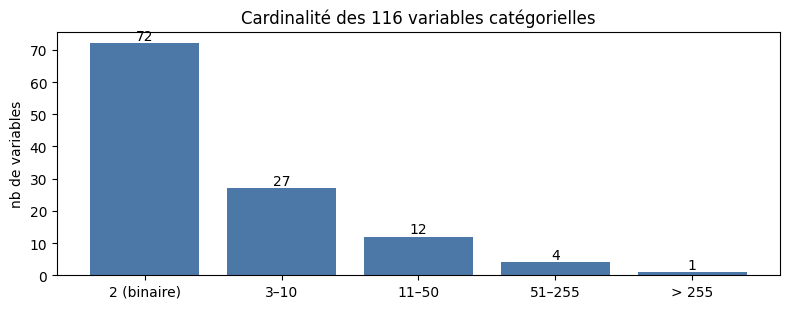

In [8]:
# --- 1.4 (b) Répartition par tranches de cardinalité -------------------------
tranches = pd.cut(card.n_union, [0, 2, 10, 50, 255, 10_000], labels=["2 (binaire)", "3–10", "11–50", "51–255", "> 255"])
rep = tranches.value_counts().sort_index().rename("nb_variables").to_frame()
rep["variables"] = [", ".join(card.index[tranches == t][:8]) + (" …" if (tranches == t).sum() > 8 else "") for t in rep.index]
display(rep)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(rep.index.astype(str), rep.nb_variables, color="#4C78A8"); ax.set_ylabel("nb de variables"); ax.set_title("Cardinalité des 116 variables catégorielles")
for i, v in enumerate(rep.nb_variables): ax.text(i, v + 1, str(v), ha="center")
plt.tight_layout(); plt.show()

**Comment lire.** La grande majorité des variables sont **binaires** (2 modalités) ; seule une poignée est à forte cardinalité. Les deux seuils utiles : **> 10** (le one-hot devient discutable) et **> 255** (limite des catégorielles natives de `HistGradientBoostingRegressor` dans scikit-learn : au-delà, il refuse la variable).

In [9]:
# --- 1.4 (c) Pourquoi le one-hot « évident » n'est pas le bon choix ----------
n_onehot = int(card.n_union.sum())
octets = len(tr) * n_onehot            # 1 octet par cellule (uint8)
print(f"colonnes après one-hot : {n_onehot} (au lieu de 116)")
print(f"mémoire d'une matrice 0/1 dense (uint8) : {octets / 1e9:.2f} Go  (float64 : {octets * 8 / 1e9:.1f} Go)")
print(f"colonnes avec au moins une modalité qui concerne < 0,1 % des lignes (rare) : "
      f"{sum((tr[c].value_counts(normalize=True) < 0.001).any() for c in CAT)} sur {len(CAT)}")

colonnes après one-hot : 1139 (au lieu de 116)
mémoire d'une matrice 0/1 dense (uint8) : 0.17 Go  (float64 : 1.4 Go)
colonnes avec au moins une modalité qui concerne < 0,1 % des lignes (rare) : 39 sur 116


**Comment lire.** Le one-hot fait passer de 116 à **1 139 colonnes**. En 0/1 compact (`uint8`) la mémoire reste modeste (≈ 0,17 Go), mais en `float64` (ce que beaucoup de modèles scikit-learn exigent) elle atteint ≈ 1,4 Go, ce qui ralentit nettement l'entraînement dans la limite de 10 minutes sur CPU. Surtout, 39 variables ont des modalités très rares : le one-hot produit des colonnes presque toujours à 0, sur lesquelles le modèle apprend du bruit. Le one-hot n'est donc pas *impossible*, mais il est lourd et peu pertinent ici.

In [10]:
# --- 1.4 (d) Modalités rares, modalités inconnues, variables inutiles --------
rares = {c: int((tr[c].value_counts() < 10).sum()) for c in CAT}
rares = {c: n for c, n in rares.items() if n}
print("variables ayant des modalités portées par < 10 lignes de train :", len(rares))
print("plus touchées :", dict(sorted(rares.items(), key=lambda kv: -kv[1])[:6]))

inconnues = {c: int((~te[c].isin(set(tr[c]))).sum()) for c in CAT}
inconnues = {c: n for c, n in inconnues.items() if n}
print("\nmodalités de a_estimer absentes de train (lignes concernées) :", inconnues if inconnues else "aucune")

quasi_const = list(card.index[card["modalite_dominante_%"] > 99.5])
print("variables quasi constantes (> 99,5 % d'une seule modalité) :", quasi_const if quasi_const else "aucune")

RESULTATS["1.4_cardinalite"] = dict(card_min=int(card.n_union.min()), card_max=int(card.n_union.max()),
    nb_binaires=int((card.n_union == 2).sum()), nb_sup_10=int((card.n_union > 10).sum()), nb_sup_255=int((card.n_union > 255).sum()),
    colonnes_onehot=n_onehot, variables_sup_255=list(card.index[card.n_union > 255]),
    modalites_inconnues_test=inconnues, quasi_constantes=quasi_const)

variables ayant des modalités portées par < 10 lignes de train : 21
plus touchées : {'cat116': 113, 'cat110': 40, 'cat109': 23, 'cat113': 13, 'cat105': 6, 'cat114': 6}

modalités de a_estimer absentes de train (lignes concernées) : {'cat89': 1, 'cat101': 1, 'cat109': 4, 'cat110': 1, 'cat116': 10}
variables quasi constantes (> 99,5 % d'une seule modalité) : ['cat15', 'cat20', 'cat21', 'cat22', 'cat34', 'cat35', 'cat47', 'cat48', 'cat55', 'cat56', 'cat58', 'cat59', 'cat60', 'cat61', 'cat62', 'cat63', 'cat64', 'cat67', 'cat68', 'cat69', 'cat70', 'cat77']


**Comment lire.**
- **Modalités rares** : une modalité vue sur < 10 lignes ne permet pas d'apprendre une vraie régularité. On peut les regrouper en « autres » (ou les laisser à un modèle à arbres qui les traite sans trop de dégâts).
- **Modalités inconnues** : si une modalité n'existe que dans `a_estimer`, aucun encodage appris sur `train` ne la connaît. Le pipeline **doit prévoir une valeur par défaut** (ex. `unknown_value=-1`), sinon il plante au moment d'estimer.
- **Variables quasi constantes** : elles n'apportent presque aucune information ; on peut les écarter (à décider en mesurant, pas en supposant).

### Décision d'encodage proposée (à justifier dans la note)

| Cardinalité | Encodage proposé | Pourquoi |
|---|---|---|
| 2 | entier 0/1 | une seule colonne, aucune perte |
| 3 à 255 | **catégoriel natif** du `HistGradientBoostingRegressor` (après codage ordinal en entiers) | pas d'explosion du nombre de colonnes ; le modèle regroupe lui-même les modalités |
| > 255 | entier ordinal traité comme numérique, ou regroupement des rares, ou encodage fréquence | le natif refuse au-delà de 255 modalités |

> **Conclusion 1.4 (journal)** : reportez les chiffres affichés (cardinalité min/max, nombre de variables binaires, > 10 et > 255, nombre de colonnes que produirait un one-hot, modalités inconnues de `a_estimer`). Le one-hot est rejeté (taille, rareté) ; le codage ordinal + catégoriel natif est retenu, avec gestion de l'inconnu.

---
# §3 · Étape 1.9 — Cibles *(profil de `loss`)*

**Ce qu'on cherche.** La cible est un **montant**, pas une classe. Ce n'est pas un détail : cela change (1) la métrique, (2) la manière de découper la validation, (3) la manière de modéliser. On vérifie d'abord que la cible est saine, puis on décrit sa forme.

In [11]:
# --- 1.9 (a) Contrôles de base -----------------------------------------------
y = tr[CIBLE]
print("type :", y.dtype, "| manquants :", int(y.isna().sum()), "| infinis :", int(np.isinf(y).sum()))
print("valeurs <= 0 :", int((y <= 0).sum()), "| min :", y.min(), "| max :", y.max())
print("valeurs distinctes :", y.nunique(), "sur", len(y), "lignes")
print("arrondi au centime (2 décimales) :", bool(np.allclose(y, y.round(2))))
print("CIBLE présente dans a_estimer :", CIBLE in te.columns)

type : float64 | manquants : 0 | infinis : 0
valeurs <= 0 : 0 | min : 0.67 | max : 121012.25
valeurs distinctes : 130784 sur 150654 lignes
arrondi au centime (2 décimales) : True
CIBLE présente dans a_estimer : False


**Comment lire.** Une cible saine pour un montant : numérique, sans manquant, **strictement positive** (min ≈ 0,67 comme l'annonce l'énoncé). Le nombre de valeurs distinctes indique une cible quasi continue (≠ une classe à quelques valeurs), donc une **régression**, pas une classification.

p0            0.7
p1          391.4
p5          618.1
p10         774.6
p25        1204.8
p50        2115.6
p75        3865.6
p90        6401.7
p95        8519.7
p99       14025.8
p99.9     24365.0
p100     121012.2

moyenne 3039 | médiane 2116 | écart-type 2915
asymétrie (skewness)  : brute 3.93 → log 0.10
aplatissement (kurtosis) : brute 53.6 → log -0.1


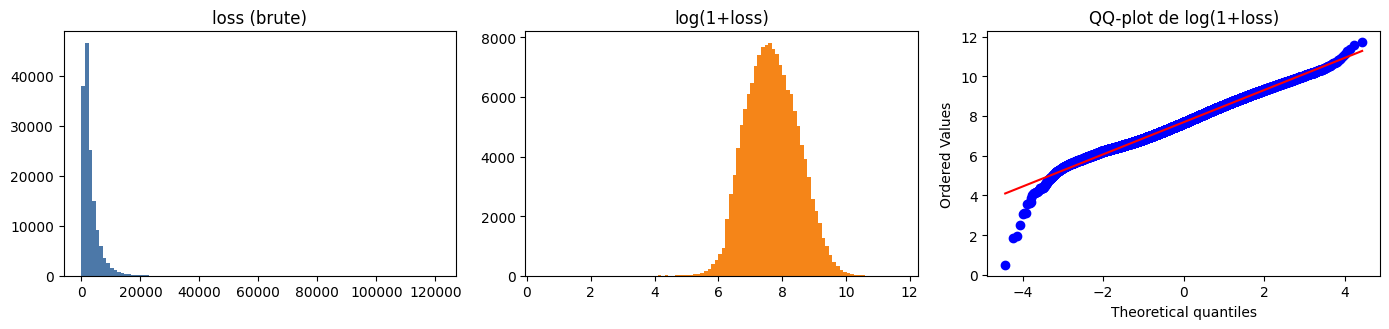

In [12]:
# --- 1.9 (b) Forme de la distribution ----------------------------------------
pct = [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 99.9, 100]
print(pd.Series(np.percentile(y, pct), index=[f"p{p}" for p in pct]).round(1).to_string())
print(f"\nmoyenne {y.mean():.0f} | médiane {y.median():.0f} | écart-type {y.std():.0f}")
print(f"asymétrie (skewness)  : brute {stats.skew(y):.2f} → log {stats.skew(np.log1p(y)):.2f}")
print(f"aplatissement (kurtosis) : brute {stats.kurtosis(y):.1f} → log {stats.kurtosis(np.log1p(y)):.1f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(y, bins=100, color="#4C78A8"); ax[0].set_title("loss (brute)")
ax[1].hist(np.log1p(y), bins=100, color="#F58518"); ax[1].set_title("log(1+loss)")
stats.probplot(np.log1p(y), dist="norm", plot=ax[2]); ax[2].set_title("QQ-plot de log(1+loss)")
plt.tight_layout(); plt.show()

**Comment lire.**
- **Asymétrie** (*skewness*) : 0 = symétrique, > 1 = très étirée à droite. Ici, ≈ 3,9 sur l'échelle brute : quelques énormes sinistres. Après passage au logarithme, elle tombe près de 0 : la distribution devient presque symétrique (même si le QQ-plot montre encore un léger écart dans les queues).
- **Kurtosis élevée** = queues très lourdes (beaucoup d'extrêmes).
- **Moyenne ≫ médiane** : la moyenne est tirée par les extrêmes ; c'est ce qui rend la **médiane** et la **MAE** plus adaptées (voir étape 1.11).

In [13]:
# --- 1.9 (c) Extrêmes : combien pèsent-ils ? ---------------------------------
q1, q3 = y.quantile([.25, .75]); seuil = q3 + 1.5 * (q3 - q1)
print(f"seuil des valeurs « extrêmes » (Q3 + 1,5 × IQR) : {seuil:.0f}")
print(f"sinistres au-dessus : {(y > seuil).sum()} ({(y > seuil).mean():.1%})")
print(f"sinistres > 10 × médiane : {(y > 10 * y.median()).sum()} | > 30 × médiane : {(y > 30 * y.median()).sum()}")

tri = np.sort(y.values)[::-1]; cum = tri.cumsum() / tri.sum()
for part in (0.01, 0.05, 0.10, 0.20):
    print(f"les {part:.0%} plus gros sinistres représentent {cum[int(part * len(y)) - 1]:.1%} du montant total")

seuil des valeurs « extrêmes » (Q3 + 1,5 × IQR) : 7857
sinistres au-dessus : 9236 (6.1%)
sinistres > 10 × médiane : 280 | > 30 × médiane : 5
les 1% plus gros sinistres représentent 6.1% du montant total
les 5% plus gros sinistres représentent 19.9% du montant total
les 10% plus gros sinistres représentent 31.9% du montant total
les 20% plus gros sinistres représentent 49.4% du montant total


**Comment lire.** La concentration est **modérée** : les 1 % de plus gros sinistres représentent 6 % du montant total, et les 10 % de plus gros ≈ 32 %. Il n'y a donc pas un tout petit nombre de dossiers qui domine : le montant est étalé, avec une queue épaisse. Seuls 5 sinistres dépassent 30 fois la médiane. Ces extrêmes ne sont **pas des erreurs** (on ne les supprime pas) : ce sont de vrais gros sinistres. On les **garde**, et on les surveille dans l'analyse d'erreurs (le modèle les sous-estimera probablement).

In [14]:
# --- 1.9 (d) Conséquence sur la validation : découper une cible continue -----
# Une classe se stratifie directement ; un montant, non : on le découpe en déciles (quantiles).
bins = pd.qcut(y, 10, labels=False)
print("effectifs par décile de loss :", np.bincount(bins))

def stabilite(cv, **kw):
    res = []
    for _, vi in cv.split(tr, **kw):
        res.append((y.iloc[vi].mean(), y.iloc[vi].median()))
    r = np.array(res); return r[:, 0].std(), r[:, 1].std()

sd_simple = stabilite(KFold(5, shuffle=True, random_state=42))
sd_strat  = stabilite(StratifiedKFold(5, shuffle=True, random_state=42), y=bins)
print(f"écart-type de la MOYENNE de loss entre les 5 plis : KFold simple {sd_simple[0]:.1f} | stratifié par déciles {sd_strat[0]:.1f}")
print(f"écart-type de la MÉDIANE de loss entre les 5 plis : KFold simple {sd_simple[1]:.1f} | stratifié par déciles {sd_strat[1]:.1f}")

RESULTATS["1.9_cible"] = dict(type=str(y.dtype), manquants=int(y.isna().sum()), min=float(y.min()), max=float(y.max()),
    mediane=float(y.median()), moyenne=round(float(y.mean()), 1), skew_brut=round(float(stats.skew(y)), 2),
    skew_log=round(float(stats.skew(np.log1p(y))), 2), part_top1pct=round(float(cum[int(0.01 * len(y)) - 1]), 3),
    sd_moyenne_plis_simple=round(float(sd_simple[0]), 1), sd_moyenne_plis_strat=round(float(sd_strat[0]), 1))

effectifs par décile de loss : [15066 15065 15065 15066 15065 15065 15066 15065 15065 15066]
écart-type de la MOYENNE de loss entre les 5 plis : KFold simple 26.9 | stratifié par déciles 7.5
écart-type de la MÉDIANE de loss entre les 5 plis : KFold simple 17.5 | stratifié par déciles 0.1


**Comment lire.** Un découpage purement aléatoire peut mettre par hasard plus de gros sinistres dans un pli que dans un autre, ce qui rend les scores des plis comparables **moins** entre eux. Le découpage **stratifié par déciles** de `loss` garantit que **chaque pli a la même répartition de petits et de gros montants** : l'écart-type de la moyenne entre plis passe ici de ≈ 27 à ≈ 7,5, et celui de la **médiane** de ≈ 17,5 à ≈ 0,1 (comparez les deux lignes affichées). C'est la réponse à la consigne de l'énoncé : *« la cible est un montant, pas une classe : cela change la façon de découper »*.

> **Conclusion 1.9 (journal)** : `loss` est numérique, sans manquant, strictement positive (0,67 → 121 012), quasi continue : **régression**. Très asymétrique (skewness ≈ 3,9 ; ≈ 0 après log) : on conserve les extrêmes (vrais sinistres), on retient la **médiane** comme constante de référence et la **MAE** comme métrique, on peut modéliser `log(1+loss)`, et on valide par `StratifiedKFold` sur les **déciles** de la cible.

---
# §4 · Étape 1.12 — Le coût des erreurs *(P4)*

**Ce qu'on cherche.** L'énoncé pose la question : *« que coûte une sous-estimation, que coûte une surestimation ? Sont-elles symétriques ? »* Pour un assureur, les deux erreurs n'ont pas les mêmes conséquences :

- **sous-estimer** un sinistre (estimé < réel) → provision insuffisante, tarif trop bas : on paie plus que prévu ;
- **surestimer** (estimé > réel) → capital immobilisé pour rien, tarif trop haut.

La **MAE** pèse un euro d'erreur de la même façon dans les deux sens : elle suppose donc un coût **symétrique**. On le **mesure** d'abord (a), puis on regarde ce que change une asymétrie (b, c). Les plis sont ceux du §3 (`StratifiedKFold` sur les déciles de `loss`), les constantes sont apprises sur le pli d'entraînement et évaluées sur le pli de validation.

In [15]:
# --- 1.12 (a) Sous-estimation vs sur-estimation avec la constante de référence ---
plis = list(StratifiedKFold(5, shuffle=True, random_state=42).split(tr, bins))
yv = y.to_numpy()
c_med, c_moy = np.empty(len(yv)), np.empty(len(yv))
for a, b in plis:
    c_med[b] = np.median(yv[a]); c_moy[b] = yv[a].mean()

e = yv - c_med                       # > 0 : sous-estimation (réel > estimé) ; < 0 : sur-estimation
sous, sur = e > 0, e < 0
abs_tot = np.abs(e).sum()
print(f"constante de référence (médiane hors-pli) : {c_med.mean():,.1f} | MAE = {np.abs(e).mean():,.1f}")
print(f"sous-estimations : {sous.mean():.1%} des dossiers | erreur moyenne {e[sous].mean():,.0f} | max {e[sous].max():,.0f} | part de l'erreur absolue totale {np.abs(e[sous]).sum() / abs_tot:.1%}")
print(f"sur-estimations  : {sur.mean():.1%} des dossiers | erreur moyenne {(-e[sur]).mean():,.0f} | max {(-e[sur]).max():,.0f} | part de l'erreur absolue totale {np.abs(e[sur]).sum() / abs_tot:.1%}")
print(f"erreur relative médiane : sous-estimation {np.median(e[sous] / yv[sous]):.0%} du réel | sur-estimation {np.median(-e[sur] / yv[sur]):.0%} du réel")

constante de référence (médiane hors-pli) : 2,115.6 | MAE = 1,810.5
sous-estimations : 50.0% des dossiers | erreur moyenne 2,734 | max 118,897 | part de l'erreur absolue totale 75.5%
sur-estimations  : 50.0% des dossiers | erreur moyenne 887 | max 2,115 | part de l'erreur absolue totale 24.5%
erreur relative médiane : sous-estimation 45% du réel | sur-estimation 76% du réel


**Comment lire.** Avec une médiane, environ la moitié des dossiers est sous-estimée et l'autre moitié surestimée. L'asymétrie ne vient pas des effectifs mais des **montants** : une cible à queue lourde donne peu de très gros sinistres sous-estimés, mais de très grosses erreurs ; les sur-estimations restent bornées (au plus la médiane elle-même). Comparez les lignes « erreur moyenne », « max » et « part de l'erreur absolue totale » : c'est là que se lit le déséquilibre. L'erreur relative montre l'autre face : une même erreur en euros est énorme pour un petit sinistre.

In [16]:
# --- 1.12 (b) Si la sous-estimation coûte k fois plus que la sur-estimation ---
# coût(e) = k·e si e > 0 (sous-estimation) ; -e si e < 0 (sur-estimation).  k = 1 : MAE.
# Le minimiseur d'un tel coût est le quantile τ = k / (1 + k) de loss (et non la médiane, sauf si k = 1).
def cout(err, k):
    return np.where(err > 0, k * err, -err)

lignes = []
for k in (0.5, 1, 2, 3, 5):
    tau = k / (1 + k)
    c_tau = np.empty(len(yv))
    for a, b in plis:
        c_tau[b] = np.quantile(yv[a], tau)
    cm, cmoy, ct = (cout(yv - c, k).mean() for c in (c_med, c_moy, c_tau))
    lignes.append(dict(k=k, tau=round(tau, 3), constante_optimale=round(float(np.quantile(yv, tau)), 1),
                       cout_mediane=round(cm, 1), cout_moyenne=round(cmoy, 1), cout_quantile_tau=round(ct, 1),
                       gain_vs_mediane_pct=round(100 * (1 - ct / cm), 1)))
tab_cout = pd.DataFrame(lignes).set_index("k")
display(tab_cout)

,tau,constante_optimale,cout_mediane,cout_moyenne,cout_quantile_tau,gain_vs_mediane_pct
k,,,,,,
0.5,0.333,1469.3,1127.0,1476.1,1041.9,7.6
1.0,0.500,2115.6,1810.5,1968.1,1810.5,0.0
2.0,0.667,3099.2,3177.4,2952.2,2951.4,7.1
3.0,0.750,3865.6,4544.3,3936.3,3794.3,16.5
5.0,0.833,4954.1,7278.2,5904.4,5026.5,30.9


**Comment lire.** `k` est le coût d'un euro sous-estimé rapporté à un euro surestimé (`k = 1` : coût symétrique, c'est la MAE). `tau` est le quantile qui minimise ce coût. Pour `k = 1` la ligne doit retrouver la médiane (gain nul). Plus `k` grandit, plus la constante optimale monte : **la bonne estimation « sans modèle » dépend du coût supposé des erreurs**, et la médiane n'est optimale que si les deux erreurs coûtent autant. La colonne `gain_vs_mediane_pct` chiffre ce que l'on perd à garder la médiane quand `k > 1`. Le rapport `k` n'est **pas mesurable dans les données** : c'est une hypothèse métier à poser et à justifier dans la note.

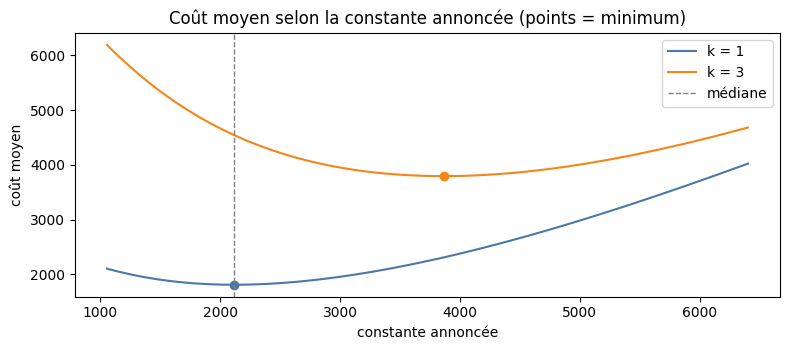

In [17]:
# --- 1.12 (c) Courbe du coût selon la constante annoncée ---------------------
grille = np.quantile(yv, np.linspace(0.20, 0.90, 71))
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, col in ((1, "#4C78A8"), (3, "#F58518")):
    courbe = [cout(yv - c, k).mean() for c in grille]
    i = int(np.argmin(courbe))
    ax.plot(grille, courbe, color=col, label=f"k = {k}")
    ax.plot(grille[i], courbe[i], "o", color=col)
ax.axvline(np.median(yv), color="grey", ls="--", lw=1, label="médiane")
ax.set_xlabel("constante annoncée"); ax.set_ylabel("coût moyen"); ax.set_title("Coût moyen selon la constante annoncée (points = minimum)")
ax.legend(); plt.tight_layout(); plt.show()

RESULTATS["1.12_cout_erreurs"] = dict(
    mae_mediane=round(float(np.abs(e).mean()), 2),
    part_sous_estimations=round(float(sous.mean()), 3), part_sur_estimations=round(float(sur.mean()), 3),
    erreur_moy_sous=round(float(e[sous].mean()), 1), erreur_moy_sur=round(float((-e[sur]).mean()), 1),
    part_erreur_abs_sous=round(float(np.abs(e[sous]).sum() / abs_tot), 3),
    couts_par_k={str(k): dict(tau=float(r.tau), constante_optimale=float(r.constante_optimale),
                              cout_mediane=float(r.cout_mediane), cout_quantile_tau=float(r.cout_quantile_tau),
                              gain_vs_mediane_pct=float(r.gain_vs_mediane_pct)) for k, r in tab_cout.iterrows()})

**Comment lire.** Chaque courbe est un coût moyen en fonction de la valeur unique annoncée ; son minimum (point) est la constante optimale pour ce `k`. Pour `k = 1` il tombe sur la médiane ; pour `k = 3` il est décalé vers le haut. Plus la courbe est plate autour du minimum, moins le choix exact de la constante compte.

> **Conclusion 1.12 (journal)** : reportez les chiffres affichés (part et taille des sous- vs sur-estimations, `tau` et constante optimale par `k`, gain par rapport à la médiane). La MAE suppose `k = 1` (coût symétrique) et conduit à la **médiane** ; si l'assureur juge la sous-estimation plus coûteuse, la décision cohérente devient un quantile supérieur (`τ = k / (1 + k)`). Le rapport `k` est une hypothèse métier, à poser explicitement dans la note de 3 pages : un modèle excellent mesuré par une métrique qui ne reflète pas ce coût reste un mauvais modèle.

---
# Bilan et sauvegarde

In [18]:
sortie = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
(sortie / "resultats_P3.json").write_text(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("écrit :", sortie / "resultats_P3.json")
print(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str))

écrit : /kaggle/working/resultats_P3.json
{
  "identite": {
    "seance": "Séance 1",
    "nom": "Faozane",
    "porteur": "P3 + P4",
    "etapes": [
      "1.6",
      "1.4",
      "1.9",
      "1.12"
    ]
  },
  "1.6_trous": {
    "valeurs_distinctes_continues": {
      "cont1": 644,
      "cont2": 33,
      "cont3": 76,
      "cont4": 112,
      "cont5": 139,
      "cont6": 2525,
      "cont7": 5439,
      "cont8": 201,
      "cont9": 340,
      "cont10": 174,
      "cont11": 324,
      "cont12": 326,
      "cont13": 352,
      "cont14": 17600
    },
    "continues_plancher": [
      "cont5"
    ],
    "nan_train": 0,
    "nan_test": 0,
    "faux_manquants_cat": {},
    "continues_valeur_dominante_sup2pct": [
      "cont1",
      "cont2",
      "cont3",
      "cont4",
      "cont5",
      "cont8",
      "cont9",
      "cont10",
      "cont11",
      "cont12",
      "cont13"
    ],
    "min_global_continues": 0.0,
    "max_global_continues": 1.0
  },
  "1.4_cardinalite": {
    "card